# 05 · 模型训练与比较

在固定的测试集上比较逻辑回归与随机森林。分类阈值暂设为 0.5，业务阈值将在下一阶段优化。

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists(): PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.models import build_preprocessor, evaluate_binary_classifier

train = pd.read_csv(PROJECT_ROOT / 'data/processed/train_precall.csv')
test = pd.read_csv(PROJECT_ROOT / 'data/processed/test_precall.csv')
X_train, y_train = train.drop(columns='target_subscription'), train['target_subscription']
X_test, y_test = test.drop(columns='target_subscription'), test['target_subscription']
RESULT_PATH = PROJECT_ROOT / 'reports/model_comparison.csv'
FIGURE_PATH = PROJECT_ROOT / 'figures/modeling/roc_curves.png'

In [2]:
models = {
    'logistic_regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'random_forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=-1, random_state=42),
}
fitted_models, probabilities, results = {}, {}, []
for name, estimator in models.items():
    pipeline = Pipeline([('preprocessor', build_preprocessor(X_train)), ('model', estimator)])
    pipeline.fit(X_train, y_train)
    probability = pipeline.predict_proba(X_test)[:, 1]
    fitted_models[name], probabilities[name] = pipeline, probability
    results.append({'model': name, **evaluate_binary_classifier(y_test, probability)})

metrics = pd.DataFrame(results).sort_values('pr_auc', ascending=False)
metrics.to_csv(RESULT_PATH, index=False)
display(metrics.style.format({column: '{:.3f}' for column in metrics.columns if column != 'model'}))

,model,roc_auc,pr_auc,precision,recall,f1
1,random_forest,0.803,0.487,0.452,0.610,0.520
0,logistic_regression,0.801,0.448,0.363,0.650,0.466


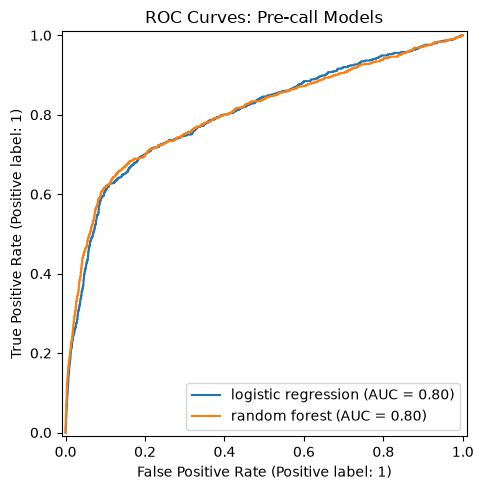

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, probability in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probability, name=name.replace('_', ' '), ax=ax)
ax.set_title('ROC Curves: Pre-call Models')
fig.tight_layout()
fig.savefig(FIGURE_PATH, dpi=160, bbox_inches='tight')
plt.show()

## 下一步

选择表现较好的模型，检查不同阈值下的精准率、召回率及可联系客户数量，再形成营销策略建议。